# WDFAB single-population GRM fitting

Single-population, single-scale adaptation of the multi-scale/multi-population
IRT pipeline in `reference_code.txt`. Baseline vs. Pairwise-imputation IRT
fits are still compared (see Section 4); everything IPW/`group_ids` and
multi-scale is dropped (see `notebook_adaptation_spec.md` for the full
rationale).

**Imputation backbone (Section 3): `MICEBayesianLOO`, not
`PairwiseOrdinalStackingModel`.** Per direct guidance from a co-author who
has run this exact pipeline on their own data, `MICEBayesianLOO` is used
with a specific tested hyperparameter recipe (see Section 3), despite
carrying a deprecation warning in favor of `PairwiseOrdinalStackingModel` in
the current `bayesianquilts`. `PairwiseOnlyImputationModel` (Section 4) and
`IrtMixedImputationModel` (Section 5) both duck-type against any MICE model
exposing `variable_names`/`variable_types`/`marginal_results`/
`univariate_results`/`predict_pmf`, which `MICEBayesianLOO` satisfies, so no
other class changes were needed to make the swap.

**GRM fitting (Section 4) already uses the right pattern.** The same
co-author flagged that joint mean-field ADVI (fitting item parameters and
person abilities together) tends to land in a poor local optimum for this
kind of model, and that full MCMC on item parameters with abilities
numerically marginalized out at each iteration works better. That is
exactly what `fit_marginal_mcmc` (used here for both Baseline and Pairwise)
already does -- no change was needed there.

## Section 0 — Setup and compatibility patches

The two patch functions below work around version-specific bugs in
`bayesianquilts`/`tensorflow_probability` (batchless marginal-ADVI training
loops, and TFP's `TransformedDistribution.entropy()` raising
`NotImplementedError` under ADVI). **If a different `bayesianquilts`/`tfp`
version is in use, check whether these are still needed before assuming they
are** — they were written against a specific pair of versions and silently
no-op (with a warning) if nothing matching is found to patch.

In [1]:
import gc
import importlib
import inspect
import itertools
import json
import os
import pickle
import sys
from pathlib import Path

os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_ENABLE_X64"] = "1"

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from bayesianquilts.imputation.mice_loo import MICEBayesianLOO
from bayesianquilts.imputation.mixed import (
    IrtMixedImputationModel,
    PairwiseOnlyImputationModel,
)
from bayesianquilts.irt.grm import GRModel


In [2]:
# -----------------------------------------------------------------------------
# Compatibility patches
# -----------------------------------------------------------------------------
def patch_all_training_loops_for_batchless_marginal_advi():
    likely_modules = [
        "bayesianquilts.training",
        "bayesianquilts.util",
        "bayesianquilts.util.training",
        "bayesianquilts.utils.training",
        "bayesianquilts.optimization",
        "bayesianquilts.inference",
        "bayesianquilts.irt.irt",
        "bayesianquilts.irt.grm",
    ]

    for module_name in likely_modules:
        try:
            importlib.import_module(module_name)
        except Exception:
            pass

    def takes_single_positional_arg(fn):
        try:
            sig = inspect.signature(fn)
        except Exception:
            return False

        params = list(sig.parameters.values())
        positional = [
            p
            for p in params
            if p.kind
            in (
                inspect.Parameter.POSITIONAL_ONLY,
                inspect.Parameter.POSITIONAL_OR_KEYWORD,
            )
        ]
        has_varargs = any(
            p.kind == inspect.Parameter.VAR_POSITIONAL for p in params
        )
        return len(positional) == 1 and not has_varargs

    def wrap_loss_if_needed(fn):
        if not callable(fn):
            return fn

        if not takes_single_positional_arg(fn):
            return fn

        def loss_fn_accepting_batch(batch, params):
            return fn(params)

        return loss_fn_accepting_batch

    def make_training_loop_compat(original_training_loop):
        if getattr(original_training_loop, "_bq_batchless_advi_wrapped", False):
            return original_training_loop

        def training_loop_compat(*args, **kwargs):
            args = list(args)
            kwargs = dict(kwargs)

            if "loss_fn" in kwargs:
                kwargs["loss_fn"] = wrap_loss_if_needed(kwargs["loss_fn"])
            else:
                for i, arg in enumerate(args):
                    if callable(arg) and takes_single_positional_arg(arg):
                        args[i] = wrap_loss_if_needed(arg)
                        break

            return original_training_loop(*args, **kwargs)

        training_loop_compat._bq_batchless_advi_wrapped = True
        training_loop_compat._bq_original_training_loop = original_training_loop
        return training_loop_compat

    patched = []

    for module_name, module in list(sys.modules.items()):
        if not module_name.startswith("bayesianquilts"):
            continue

        if hasattr(module, "training_loop"):
            original = getattr(module, "training_loop")
            if callable(original):
                setattr(module, "training_loop", make_training_loop_compat(original))
                patched.append(module_name)

    for cls in [GRModel] + list(GRModel.__mro__):
        method = getattr(cls, "fit_marginal_advi", None)
        if method is None:
            continue

        globals_dict = getattr(method, "__globals__", None)
        if globals_dict is None and hasattr(method, "__func__"):
            globals_dict = method.__func__.__globals__

        if globals_dict and "training_loop" in globals_dict:
            original = globals_dict["training_loop"]
            if callable(original):
                globals_dict["training_loop"] = make_training_loop_compat(original)
                patched.append(f"{cls.__name__}.__globals__")

    if not patched:
        print("WARNING: Did not find a training_loop to patch. ADVI may still fail.")
    else:
        print(
            "Applied bayesianquilts marginal ADVI training_loop compatibility patch to: "
            + ", ".join(sorted(set(patched)))
        )


def patch_tfp_transformed_distribution_entropy_for_advi():
    import tensorflow_probability.substrates.jax as tfp

    tfd = tfp.distributions
    cls = tfd.TransformedDistribution

    if getattr(cls, "_bq_entropy_patch_applied", False):
        return

    original_entropy = cls._entropy

    def entropy_compat(self, **kwargs):
        try:
            return original_entropy(self, **kwargs)
        except NotImplementedError:
            return self.distribution.entropy()

    cls._entropy = entropy_compat
    cls._bq_entropy_patch_applied = True

    print("Applied TFP TransformedDistribution entropy fallback patch for ADVI.")


patch_all_training_loops_for_batchless_marginal_advi()
patch_tfp_transformed_distribution_entropy_for_advi()


Applied bayesianquilts marginal ADVI training_loop compatibility patch to: bayesianquilts.model, bayesianquilts.util, bayesianquilts.vi.minibatch
Applied TFP TransformedDistribution entropy fallback patch for ADVI.


In [3]:
# -----------------------------------------------------------------------------
# Config
# -----------------------------------------------------------------------------
DATA_PATH = Path("/home/luis/CGE/mice_imp/data_wdfab/WDFAB_ExperimentalData_CMCommonItem_Jul2026.dta")
OUTPUT_PATH = Path("/home/luis/CGE/mice_imp/data_wdfab/wdfab_results")

MICE_LOO_MODEL_PATH = OUTPUT_PATH / "mice_bayesian_loo_model.yaml"
MICE_LOO_SAVE_DIR = OUTPUT_PATH / "mice_loo_incremental"

RESP_CARDINALITY = 5

# Which already-fitted standardized IRT model to condition the BCM on.
#
# Changed from "pairwise" to "baseline": per the co-author's findings, a
# bias-adjustment regression fit on the raw (non-imputed) model does about
# as well as one fit on the imputed model, so there's no reason to pay for
# the full Pairwise IRT MCMC fit before building the BCM.
BCM_SOURCE = "baseline"  # "baseline" or "pairwise"

# MCMC / ADVI settings for the GRM fits, carried over from the reference
# script's argparse defaults.
NUM_CHAINS = 4
NUM_WARMUP = 3000
NUM_SAMPLES = 2000

STEP_SIZE = 0.002               # Baseline MCMC initial step size
PAIRWISE_STEP_SIZE = 0.0005     # Pairwise-imputed MCMC initial step size (usually smaller)
TARGET_ACCEPT_PROB = 0.95       # Baseline
PAIRWISE_TARGET_ACCEPT_PROB = 0.98  # Pairwise-imputed

ADVI_ITERATIONS = 100           # Approximate total baseline ADVI iterations for MCMC warm-start
ADVI_NUM_SAMPLES = 32
ADVI_LEARNING_RATE = 0.00051
ADVI_RANK = 0

BATCH_SIZE = 512
SEED = 42

N_TOP_FEATURES = 30  # MICEBayesianLOO candidate-predictor cap; resolved explicitly in Section 3

# MICEBayesianLOO hyperparameters -- the co-author's tested recipe, run on
# their own dataset. inference_method="advi" was found more robust than the
# class default ("pathfinder") for this kind of data.
MICE_N_IMPUTATIONS = 5
MICE_MAX_ITER = 5
MICE_MIN_OBS = 20
MICE_PATHFINDER_MAXITER = 1000
MICE_PATHFINDER_NUM_SAMPLES = 200
MICE_PRIOR_SCALE = 0.5
MICE_BATCH_SIZE = 512
MICE_INFERENCE_METHOD = "advi"
MICE_VERBOSE = False
MICE_N_JOBS = -1  # co-author used 4 on their system; we have 32 cores, so use all of them

COLORS = {"Baseline": "#4477AA", "Pairwise": "#228833"}
MARKERS = {"Baseline": "o", "Pairwise": "D"}

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)


## Section 1 — Load and validate data

Loads the single-population WDFAB `.dta` file and derives ordinal response
codes via `.cat.codes` (pandas' `-1` missing sentinel mapped to `NaN`).

**Documented assumption (confirmed by the user directly, not derived):** the
three `_r`-suffixed items (`DA062_r`, `DA063_r`, `DA069_r`) are already
reverse-coded in the source `.dta`. No reversal transform is applied to them
anywhere in this notebook — they are treated identically to all other items.

**Documented fallback (verified against this exact file, not assumed):**
those same three `_r` items have no Stata value-label set attached, so
`pd.read_stata(..., convert_categoricals=True)` returns them as plain
`float32` (raw values `1.0`–`5.0`) instead of `category`. Checked
empirically on three labeled items in this file (`DA061`, `DA051`,
`DA074`): `col.cat.codes` equals `raw_value - 1` exactly, everywhere,
including on missing values (`NaN` in both). The loader below applies that
same `raw_value - 1` transform directly to the three non-categorical items
as a fallback, and reports which items triggered it — it does not silently
guess for an item this hasn't been checked against.

In [4]:
ITEM_KEYS = [
    "DA051", "DA053", "DA054", "DA055", "DA058", "DA060", "DA061",
    "DA062_r", "DA063_r", "DA064", "DA066", "DA067", "DA052", "DA068",
    "DA069_r", "DA070", "DA071", "DA072", "DA073", "DA074",
]


def load_wdfab_single_population(dta_path, item_keys=ITEM_KEYS):
    """
    Load a single-population WDFAB dataset from a Stata .dta file and
    return an ordinal response matrix ready for GRM fitting.

    Uses convert_categoricals=True, then derives integer ordinal codes
    from the categorical labels via .cat.codes. Pandas' .cat.codes
    convention: valid categories -> 0-indexed integers, missing -> -1
    (here mapped to NaN instead, since the GRM expects NaN for missing).

    IMPORTANT: .cat.codes is 0-indexed *relative to the categories your
    data actually contains*. If some item never has, say, its lowest
    response category observed in this sample, that item's codes will
    not align with its true 0..(K-1) response range. Section 1's
    diagnostic cell below checks this per item before anything downstream
    trusts it.

    FALLBACK: some items may have no Stata value-label set attached, so
    they come back as plain numeric dtype instead of category. Verified on
    this exact file (see the Section 1 markdown cell above) that
    col.cat.codes == raw_value - 1 for labeled items, so that same
    transform is applied directly to non-categorical numeric items. Any
    item that isn't categorical AND doesn't look like a clean small-integer
    ordinal (non-missing values not all integer-valued) still fails loudly
    -- this fallback is not a silent catch-all.
    """
    dta_path = Path(dta_path).expanduser()

    df = pd.read_stata(
        dta_path,
        convert_categoricals=True,
        convert_dates=True,
        preserve_dtypes=True,
    )

    missing_items = [k for k in item_keys if k not in df.columns]
    if missing_items:
        raise KeyError(f"Items not found in .dta columns: {missing_items}")

    responses = {}
    fallback_items = []

    for item in item_keys:
        col = df[item]

        if isinstance(col.dtype, pd.CategoricalDtype):
            codes = col.cat.codes.astype(np.float64)
            codes = codes.replace(-1, np.nan)  # pandas' missing sentinel -> NaN
        else:
            non_missing = col.dropna()
            is_clean_ordinal = (
                pd.api.types.is_numeric_dtype(col)
                and len(non_missing) > 0
                and np.all(np.mod(non_missing.to_numpy(), 1) == 0)
            )
            if not is_clean_ordinal:
                raise TypeError(
                    f"Column '{item}' is neither categorical nor a clean "
                    f"small-integer numeric column after "
                    f"convert_categoricals=True (dtype={col.dtype}). "
                    "Check the .dta value label mapping for this item."
                )

            fallback_items.append(item)
            codes = (col.astype(np.float64) - 1.0)

        responses[item] = codes

    if fallback_items:
        print(
            "Fallback applied (no Stata value labels; used raw_value - 1 "
            f"directly): {fallback_items}"
        )

    responses = pd.DataFrame(responses, index=df.index)

    return {
        "responses": responses,
        "item_keys": item_keys,
        "num_people": len(responses),
        "fallback_items": fallback_items,
    }


loaded = load_wdfab_single_population(DATA_PATH)
responses = loaded["responses"]
item_keys = loaded["item_keys"]
num_people = loaded["num_people"]

print(f"num_people: {num_people}")
print(f"num_items: {len(item_keys)}")


Fallback applied (no Stata value labels; used raw_value - 1 directly): ['DA062_r', 'DA063_r', 'DA069_r']
num_people: 1363
num_items: 20


In [5]:
# Diagnostic: per-item observed category counts and code-range check.
#
# The GRM's response_cardinality argument assumes every item shares the
# same ordinal range (0..K-1 for the same K across all items). This is a
# manual check the user needs to eyeball -- do not silently proceed if any
# item's code range doesn't match the rest.

category_counts = {}
observed_ranges = {}

for item in item_keys:
    vc = responses[item].value_counts(dropna=False).sort_index()
    category_counts[item] = dict(vc)
    non_missing = responses[item].dropna()
    observed_ranges[item] = (
        (int(non_missing.min()), int(non_missing.max()))
        if len(non_missing) > 0
        else None
    )

print("Per-item response category counts:")
for item in item_keys:
    print(f"  {item}: {category_counts[item]}")

print("\nPer-item observed code range (min, max):")
for item in item_keys:
    print(f"  {item}: {observed_ranges[item]}")

expected_range = (0, RESP_CARDINALITY - 1)
mismatched_items = [
    item
    for item, rng in observed_ranges.items()
    if rng is not None and rng != expected_range
]

missingness_per_item = responses.isna().mean()
overall_missingness = responses.isna().to_numpy().mean()

print(f"\nTotal respondents: {num_people}")
print("\nMissingness rate per item:")
for item in item_keys:
    print(f"  {item}: {missingness_per_item[item]:.4f}")
print(f"\nOverall missingness rate across the response matrix: {overall_missingness:.4f}")


Per-item response category counts:
  DA051: {0.0: np.int64(135), 1.0: np.int64(129), 2.0: np.int64(85), 3.0: np.int64(53), 4.0: np.int64(42), nan: np.int64(919)}
  DA053: {0.0: np.int64(293), 1.0: np.int64(81), 2.0: np.int64(10), 3.0: np.int64(5), 4.0: np.int64(45), nan: np.int64(929)}
  DA054: {0.0: np.int64(420), 1.0: np.int64(373), 2.0: np.int64(180), 3.0: np.int64(126), 4.0: np.int64(183), nan: np.int64(81)}
  DA055: {0.0: np.int64(85), 1.0: np.int64(116), 2.0: np.int64(58), 3.0: np.int64(88), 4.0: np.int64(77), nan: np.int64(939)}
  DA058: {0.0: np.int64(426), 1.0: np.int64(301), 2.0: np.int64(202), 3.0: np.int64(143), 4.0: np.int64(203), nan: np.int64(88)}
  DA060: {0.0: np.int64(715), 1.0: np.int64(276), 2.0: np.int64(95), 3.0: np.int64(49), 4.0: np.int64(142), nan: np.int64(86)}
  DA061: {0.0: np.int64(296), 1.0: np.int64(70), 2.0: np.int64(17), 3.0: np.int64(2), 4.0: np.int64(37), nan: np.int64(941)}
  DA062_r: {0.0: np.int64(92), 1.0: np.int64(83), 2.0: np.int64(110), 3.0: np

In [6]:
if mismatched_items:
    display(Markdown(
        "### ⚠️ Category-range mismatch detected\n\n"
        f"`response_cardinality={RESP_CARDINALITY}` assumes every item's "
        f"observed codes span `{expected_range}`. The following items do "
        "**not** match that range in this sample:\n\n"
        + "\n".join(
            f"- `{item}`: observed range {observed_ranges[item]}"
            for item in mismatched_items
        )
        + "\n\n**Do not proceed to model fitting until this is resolved** "
        "-- either the item genuinely has fewer/more response categories "
        "than assumed, or a category is simply unobserved in this sample "
        "(rare-category sparsity) and `response_cardinality` still applies. "
        "Decide which case this is before continuing."
    ))
else:
    display(Markdown(
        "### ✅ Category-range check passed\n\n"
        f"All {len(item_keys)} items have observed codes spanning exactly "
        f"`{expected_range}`, consistent with `response_cardinality={RESP_CARDINALITY}`."
    ))


### ✅ Category-range check passed

All 20 items have observed codes spanning exactly `(0, 4)`, consistent with `response_cardinality=5`.

## Section 2 — Build the data dict

Simplified relative to the reference script's `make_data_dict`: no
`group_ids` parameter, no `sample_weights` key (no IPW with a single
population).

In [7]:
def make_data_dict(dataframe):
    data = {col: dataframe[col].to_numpy().astype(np.float64) for col in dataframe.columns}
    data["person"] = np.arange(len(dataframe), dtype=np.float64)
    return data


data_dict = make_data_dict(responses[item_keys])
print(f"Data dict keys: {list(data_dict.keys())}")


Data dict keys: ['DA051', 'DA053', 'DA054', 'DA055', 'DA058', 'DA060', 'DA061', 'DA062_r', 'DA063_r', 'DA064', 'DA066', 'DA067', 'DA052', 'DA068', 'DA069_r', 'DA070', 'DA071', 'DA072', 'DA073', 'DA074', 'person']


## Section 3 — Fit the shared MICEBayesianLOO imputation model

Fit once and cache to disk. Uses `MICEBayesianLOO`, not
`PairwiseOrdinalStackingModel` -- despite the deprecation warning on this
class in the current `bayesianquilts`, this is the co-author's directly
tested recipe (hyperparameters carried over from their own run, `n_jobs`
bumped from their `4` to `-1` since this machine has 32 cores available).
Fit once, reused as the shared imputation backbone for both the Pairwise
IRT variant (Section 4) and, if `BCM_SOURCE="pairwise"`, the BCM (Section
5).

With only 20 items, `n_top_features` will resolve to using all of the
other 19 as candidate predictors -- made explicit below rather than left
implicit.

In [8]:
resolved_n_top_features = min(N_TOP_FEATURES, len(item_keys) - 1)
print(
    f"n_top_features configured={N_TOP_FEATURES}, "
    f"available predictors={len(item_keys) - 1} -> resolved={resolved_n_top_features} "
    f"({'all other items used' if resolved_n_top_features == len(item_keys) - 1 else 'subset used'})"
)

if MICE_LOO_MODEL_PATH.exists():
    print(f"Loading existing MICEBayesianLOO imputation model: {MICE_LOO_MODEL_PATH}")
    mice_loo_model = MICEBayesianLOO.load(str(MICE_LOO_MODEL_PATH))
else:
    print("Fitting MICEBayesianLOO imputation model...")

    mice_loo_model = MICEBayesianLOO(
        n_imputations=MICE_N_IMPUTATIONS,
        max_iter=MICE_MAX_ITER,
        verbose=MICE_VERBOSE,
        min_obs=MICE_MIN_OBS,
        pathfinder_maxiter=MICE_PATHFINDER_MAXITER,
        pathfinder_num_samples=MICE_PATHFINDER_NUM_SAMPLES,
        prior_scale=MICE_PRIOR_SCALE,
        batch_size=MICE_BATCH_SIZE,
        inference_method=MICE_INFERENCE_METHOD,
    )

    # n_jobs=-1: per-target univariate fits are embarrassingly parallel over
    # joblib, so this uses all available cores (32 here).
    mice_loo_model.fit_loo_models(
        responses[item_keys],
        save_dir=MICE_LOO_SAVE_DIR,
        n_jobs=MICE_N_JOBS,
        n_top_features=resolved_n_top_features,
        seed=SEED,
    )

    mice_loo_model.save(str(MICE_LOO_MODEL_PATH))
    print(f"Saved MICEBayesianLOO imputation model to {MICE_LOO_MODEL_PATH}")


n_top_features configured=30, available predictors=19 -> resolved=19 (all other items used)
Fitting MICEBayesianLOO imputation model...


/tmp/ipykernel_352828/2535271966.py:14: DeprecationWarning: MICEBayesianLOO is deprecated. Use bayesianquilts.imputation.pairwise_stacking.PairwiseOrdinalStackingModel instead.
  mice_loo_model = MICEBayesianLOO(
Target: DA074: 100%|██████████| 20/20 [02:19<00:00,  6.96s/it]          


Saved MICEBayesianLOO imputation model to /home/luis/CGE/mice_imp/data_wdfab/wdfab_results/mice_bayesian_loo_model.yaml


In [17]:
# Per-feature regression coefficients from the fitted MICEBayesianLOO
# univariate models: for each (target, predictor) pair actually fitted,
# mice_loo_model.univariate_results holds a UnivariateModelResult with
# beta_mean (the fitted coefficient) and intercept_mean, plus
# elpd_loo_per_obs as a measure of how predictive that feature actually is.
coef_rows = []
for (target_idx, predictor_idx), result in mice_loo_model.univariate_results.items():
    coef_rows.append({
        "target": mice_loo_model.variable_names[target_idx],
        "predictor": mice_loo_model.variable_names[predictor_idx],
        "beta_mean": result.beta_mean,
        "intercept_mean": result.intercept_mean,
        "n_obs": result.n_obs,
        "elpd_loo_per_obs": result.elpd_loo_per_obs,
        "khat_max": result.khat_max,
        "converged": result.converged,
    })

coefficients_df = pd.DataFrame(coef_rows).sort_values(
    ["target", "elpd_loo_per_obs"], ascending=[True, False]
)
print(f"{len(coefficients_df)} (target, predictor) coefficient rows")
coefficients_df


250 (target, predictor) coefficient rows


,target,predictor,beta_mean,intercept_mean,n_obs,elpd_loo_per_obs,khat_max,converged
3,DA051,DA055,"[0.13972807, 0.61664945, 0.57161903, 0.7121479]",None,417,-1.450327,0.462312,True
2,DA051,DA054,"[0.51884323, 0.6192011, 0.6603258, 0.5777601]",None,420,-1.458474,0.414466,True
8,DA051,DA061,"[1.0310267, 0.5496152, 0.32007572, 0.26925343]",None,415,-1.462189,0.357364,True
4,DA051,DA064,"[0.55411756, 0.5972121, 0.54421765, 0.58376867]",None,412,-1.464448,0.524514,True
1,DA051,DA058,"[0.37767863, 0.5805374, 0.52156997, 0.56504786]",None,421,-1.466671,0.520332,True
...,...,...,...,...,...,...,...,...
245,DA074,DA060,"[0.20619892, 0.39516437, 0.33475822, 0.21111004]",None,409,-1.167389,0.634399,True
248,DA074,DA054,"[-0.08875882, 0.29820365, 0.35255554, 0.2834122]",None,410,-1.174705,0.436479,True
249,DA074,DA062_r,"[-0.059870765, 0.09970535, 0.22185105, 0.2847244]",None,405,-1.183804,0.426609,True
246,DA074,DA066,"[0.13578558, 0.11941694, 0.15601265, 0.12736218]",None,411,-1.233189,0.651200,True


## Section 4 — Fit Baseline and Pairwise IRT models

Ported from the reference script's `fit_irt_mcmc_variant`
(ADVI warm-start -> MCMC -> R-hat check -> standardize -> EAP), called
twice:

1. **Baseline**: `imputation_model=None`, `run_advi=True`, `init_advi_params=None`
2. **Pairwise**: `imputation_model=PairwiseOnlyImputationModel(mice_model=mice_loo_model)`,
   `run_advi=False`, `init_advi_params=<Baseline's advi_params>` (reuses
   Baseline's ADVI warm-start rather than running its own ADVI)

The R-hat gate (`> 1.05`) is a visible warning, not a silent pass -- the fit
still proceeds past it (matching the reference script), but the warning is
rendered as a markdown cell so it can't be missed in scrolled-past log
output.

**Note on multi-core hardware:** `NUM_CHAINS` chains run in a sequential
Python loop inside `fit_marginal_mcmc` in the installed `bayesianquilts`
(not `pmap`'d across devices), so extra cores don't parallelize the 4
chains against each other. Each chain's internal `vmap`-over-people
computations do already use JAX's default CPU intra-op threading (all
available cores), so a single chain is not single-threaded -- it's just
that the 4 chains don't run concurrently.

In [9]:
def compute_steps_per_epoch(num_people, batch_size):
    batch_size = min(int(batch_size), int(num_people))
    steps_per_epoch = int(np.ceil(num_people / batch_size))
    return batch_size, steps_per_epoch


def eap_to_1d(eap_result):
    return np.asarray(eap_result["eap"]).reshape(-1)


def print_rhat(mcmc_samples, prefix="  "):
    max_rhat_overall = 0.0

    for var_name, samples in mcmc_samples.items():
        arr = np.asarray(samples)

        if arr.ndim < 2 or arr.shape[0] < 2:
            continue

        chain_means = np.mean(arr, axis=1)
        between_var = np.var(chain_means, axis=0, ddof=1)
        within_var = np.mean(np.var(arr, axis=1, ddof=1), axis=0)
        n = arr.shape[1]

        r_hat = np.sqrt(
            ((n - 1) / n * within_var + between_var)
            / np.maximum(within_var, 1e-30)
        )

        max_rhat = float(np.max(r_hat))
        max_rhat_overall = max(max_rhat_overall, max_rhat)

        print(
            f"{prefix}{var_name} R-hat: "
            f"mean={np.mean(r_hat):.4f}, max={max_rhat:.4f}"
        )

    print(f"{prefix}Max R-hat overall: {max_rhat_overall:.4f}")
    return max_rhat_overall


def summarize_mcmc_samples(mcmc_samples):
    stats = {}

    for k, v in mcmc_samples.items():
        arr = np.asarray(v)
        flat = arr.reshape(-1, *arr.shape[2:])

        stats[k] = {
            "mean": np.mean(flat, axis=0),
            "std": np.std(flat, axis=0),
        }

    return stats


def attach_imputation_pmfs(model, data):
    out = dict(data)

    if getattr(model, "imputation_model", None) is None:
        return out

    pmfs, weights = model._compute_batch_pmfs(out)

    if pmfs is not None:
        out["_imputation_pmfs"] = pmfs

    if weights is not None:
        out["_imputation_weights"] = weights

    return out


def fit_marginal_advi_warmstart(
    model, data, num_samples, advi_iterations, learning_rate, rank, seed, steps_per_epoch,
):
    num_epochs = max(1, int(np.ceil(advi_iterations / steps_per_epoch)))

    print(
        f"  ADVI warm-start: requested_iterations={advi_iterations}, "
        f"steps_per_epoch={steps_per_epoch}, num_epochs={num_epochs}, "
        f"actual_steps≈{num_epochs * steps_per_epoch}"
    )

    return model.fit_marginal_advi(
        data,
        data_iterator=itertools.repeat(None),
        steps_per_epoch=steps_per_epoch,
        num_samples=num_samples,
        num_epochs=num_epochs,
        learning_rate=learning_rate,
        rank=rank,
        seed=seed,
        verbose=True,
    )


In [10]:
def fit_irt_mcmc_variant(
    variant_name,
    item_keys,
    variant_data,
    num_people,
    response_cardinality,
    output_dir,
    num_chains,
    num_warmup,
    num_samples,
    step_size,
    target_accept_prob,
    advi_iterations,
    advi_num_samples,
    advi_learning_rate,
    advi_rank,
    batch_size,
    seed,
    imputation_model=None,
    run_advi=True,
    init_advi_params=None,
):
    print(f"\n--- {variant_name}: IRT setup ---")

    model = GRModel(
        item_keys=item_keys,
        num_people=num_people,
        response_cardinality=response_cardinality,
        dim=1,
        imputation_model=imputation_model,
        dtype=jnp.float64,
    )

    if imputation_model is not None:
        try:
            model.validate_imputation_model()
            print(f"  {variant_name}: imputation model validation passed.")
        except Exception as e:
            print(f"  {variant_name}: imputation validation warning: {e}")

    model_data = attach_imputation_pmfs(model, variant_data)

    actual_batch_size, steps_per_epoch = compute_steps_per_epoch(num_people, batch_size)
    print(
        f"  ADVI batching metadata: num_people={num_people}, "
        f"batch_size={actual_batch_size}, steps_per_epoch={steps_per_epoch}"
    )

    advi_losses = np.array([])
    advi_params = None

    if run_advi:
        print(f"\n--- {variant_name}: IRT marginal ADVI warm-start ---")

        advi_losses, advi_params = fit_marginal_advi_warmstart(
            model=model,
            data=model_data,
            num_samples=advi_num_samples,
            advi_iterations=advi_iterations,
            learning_rate=advi_learning_rate,
            rank=advi_rank,
            seed=seed,
            steps_per_epoch=steps_per_epoch,
        )

        print("  ADVI warm-start completed. EAP will be computed after MCMC.")

    elif init_advi_params is not None:
        print(f"\n--- {variant_name}: using supplied ADVI params to initialize MCMC ---")
        model.params = init_advi_params
        advi_params = init_advi_params

    else:
        print(f"\n--- {variant_name}: no ADVI params supplied; MCMC will use default initialization ---")

    print(f"\n--- {variant_name}: IRT marginal MCMC ---")
    print(
        f"  MCMC settings: chains={num_chains}, warmup={num_warmup}, "
        f"samples={num_samples}, step_size={step_size}, "
        f"target_accept_prob={target_accept_prob}"
    )

    mcmc_samples = model.fit_marginal_mcmc(
        model_data,
        theta_grid=None,
        num_chains=num_chains,
        num_warmup=num_warmup,
        num_samples=num_samples,
        target_accept_prob=target_accept_prob,
        step_size=step_size,
        seed=seed + 10000,
        verbose=True,
    )

    max_rhat = print_rhat(mcmc_samples)

    if max_rhat > 1.05:
        display(Markdown(
            f"### ⚠️ {variant_name}: R-hat gate failed\n\n"
            f"Max R-hat = **{max_rhat:.4f}** (> 1.05). Posterior summaries "
            "from this fit should not be trusted as-is. The fit is "
            "proceeding anyway (matching the reference script's behavior), "
            "but consider increasing warmup/samples and lowering step_size "
            "before relying on these results."
        ))

    eap_pre = model.compute_eap_abilities(model_data)
    print(
        f"  Pre-std EAP: mean={float(jnp.mean(eap_pre['eap'])):.4f}, "
        f"std={float(jnp.std(eap_pre['eap'])):.4f}, "
        f"PSD={float(jnp.mean(eap_pre['psd'])):.4f}"
    )

    standardize_stats = model.standardize_marginal(model_data)

    eap_post = model.compute_eap_abilities(model_data)
    print(
        f"  Post-std EAP: mean={float(jnp.mean(eap_post['eap'])):.4f}, "
        f"std={float(jnp.std(eap_post['eap'])):.4f}, "
        f"PSD={float(jnp.mean(eap_post['psd'])):.4f}"
    )

    model.fit_surrogate_to_mcmc()

    eap_arr = np.asarray(eap_post["eap"]).reshape(-1)
    model.surrogate_sample["abilities"] = jnp.array(
        eap_arr[:, np.newaxis, np.newaxis, np.newaxis]
    )[np.newaxis, ...]

    model_path = output_dir / f"grm_mcmc_{variant_name.lower()}"
    model.save_to_disk(model_path)

    return {
        "model": model,
        "data": model_data,
        "mcmc_samples": mcmc_samples,
        "eap": eap_to_1d(eap_post),
        "psd": np.asarray(eap_post["psd"]),
        "advi_losses": np.asarray(advi_losses),
        "advi_params": advi_params,
        "max_rhat": max_rhat,
        "standardize_stats": standardize_stats,
        "stats": summarize_mcmc_samples(mcmc_samples),
        "model_path": model_path,
        "advi_was_run": bool(run_advi),
        "mcmc_step_size": step_size,
        "mcmc_target_accept_prob": target_accept_prob,
    }


In [11]:
baseline_res = fit_irt_mcmc_variant(
    variant_name="Baseline",
    item_keys=item_keys,
    variant_data=data_dict,
    num_people=num_people,
    response_cardinality=RESP_CARDINALITY,
    output_dir=OUTPUT_PATH,
    num_chains=NUM_CHAINS,
    num_warmup=NUM_WARMUP,
    num_samples=NUM_SAMPLES,
    step_size=STEP_SIZE,
    target_accept_prob=TARGET_ACCEPT_PROB,
    advi_iterations=ADVI_ITERATIONS,
    advi_num_samples=ADVI_NUM_SAMPLES,
    advi_learning_rate=ADVI_LEARNING_RATE,
    advi_rank=ADVI_RANK,
    batch_size=BATCH_SIZE,
    seed=SEED,
    imputation_model=None,
    run_advi=True,
    init_advi_params=None,
)



--- Baseline: IRT setup ---
  ADVI batching metadata: num_people=1363, batch_size=512, steps_per_epoch=3

--- Baseline: IRT marginal ADVI warm-start ---
  ADVI warm-start: requested_iterations=100, steps_per_epoch=3, num_epochs=34, actual_steps≈102
Marginal ADVI (Rao-Blackwellized abilities)
  Item vars: ['difficulties0', 'discriminations', 'ddifficulties']
  Surrogate params: 240
  Rank: 0 (mean-field)
--- Starting Training ---
Patience for early stopping: 3 epochs
LR decay factor on plateau: 0.5
Convergence will be checked every: 1 epoch(s)
Checkpoints will be saved to: None
Optimizing keys: ['mu\\identity\\normal\\loc', 'mu\\identity\\normal\\scale', 'difficulties0\\identity\\normal\\loc', 'difficulties0\\identity\\normal\\scale', 'discriminations\\softplus\\normal\\loc', 'discriminations\\softplus\\normal\\scale', 'ddifficulties\\softplus\\normal\\loc', 'ddifficulties\\softplus\\normal\\scale']
-------------------------
  -> New best loss found. Checkpoint saved.                  

In [12]:
pairwise_only = PairwiseOnlyImputationModel(mice_model=mice_loo_model)

pairwise_res = fit_irt_mcmc_variant(
    variant_name="Pairwise",
    item_keys=item_keys,
    variant_data=data_dict,
    num_people=num_people,
    response_cardinality=RESP_CARDINALITY,
    output_dir=OUTPUT_PATH,
    num_chains=NUM_CHAINS,
    num_warmup=NUM_WARMUP,
    num_samples=NUM_SAMPLES,
    step_size=PAIRWISE_STEP_SIZE,
    target_accept_prob=PAIRWISE_TARGET_ACCEPT_PROB,
    advi_iterations=ADVI_ITERATIONS,
    advi_num_samples=ADVI_NUM_SAMPLES,
    advi_learning_rate=ADVI_LEARNING_RATE,
    advi_rank=ADVI_RANK,
    batch_size=BATCH_SIZE,
    seed=SEED + 1,
    imputation_model=pairwise_only,
    run_advi=False,
    init_advi_params=baseline_res["advi_params"],
)



--- Pairwise: IRT setup ---
  Pairwise: imputation model validation passed.
  ADVI batching metadata: num_people=1363, batch_size=512, steps_per_epoch=3

--- Pairwise: using supplied ADVI params to initialize MCMC ---

--- Pairwise: IRT marginal MCMC ---
  MCMC settings: chains=4, warmup=3000, samples=2000, step_size=0.0005, target_accept_prob=0.98
Marginal MCMC (Rao-Blackwellized abilities)
  Item params: ['difficulties0', 'discriminations', 'ddifficulties']
  Total dimensions: 100
  Quadrature: 31-point Gauss-Hermite
  Chains: 4, Warmup: 3000, Samples: 2000
  Initializing from ADVI solution
  Flat parameter vector: 100 elements
  Mass matrix: diagonal

  Chain 1/4: window_adaptation warmup
    warmup done. adapted step_size=2.6108e-02
    Sampling (2000 steps → 2000 kept, step_size=0.026108)...
    Non-divergent ratio: 0.043

  Chain 2/4: window_adaptation warmup
    warmup done. adapted step_size=1.0101e-02
    Sampling (2000 steps → 2000 kept, step_size=0.010101)...
    Non-diverg

## Section 5 — Build the BCM (mixed imputation / bias-adjustment) artifact

Conditioned on whichever of Baseline/Pairwise `BCM_SOURCE` names (default
now `"baseline"` -- see the config-cell comment in Section 0 for why: the
co-author found a bias-adjustment regression fit on the raw model does
about as well as one fit on the imputed model, so this skips paying for
the full Pairwise IRT MCMC fit by default).

In [13]:
def save_bcm_model_artifact(model, path, source_model_path=None, source_name=None):
    path = Path(path).expanduser()
    path.mkdir(parents=True, exist_ok=True)

    saved = False

    if hasattr(model, "save_to_disk"):
        try:
            model.save_to_disk(path)
            saved = True
        except Exception as e:
            print(f"BCM save_to_disk failed: {e}")

    if not saved and hasattr(model, "save"):
        try:
            model.save(str(path))
            saved = True
        except Exception as e:
            print(f"BCM save failed: {e}")

    try:
        with open(path / "bcm_model.pkl", "wb") as f:
            pickle.dump(model, f)
        saved = True
    except Exception as e:
        print(f"BCM pickle save failed: {e}")

    if hasattr(model, "weights"):
        try:
            with open(path / "weights.json", "w") as f:
                json.dump(model.weights, f, indent=2)
        except Exception as e:
            print(f"Could not save BCM weights: {e}")

    metadata = {
        "description": "BCM / mixed imputation model built after fitting and standardizing IRT.",
        "source_model_path": str(source_model_path) if source_model_path is not None else None,
        "source_name": source_name,
        "is_irt_fit": False,
        "conditional_on_prefit_irt": True,
    }

    with open(path / "metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    return saved


print(f"--- Build BCM conditional on {BCM_SOURCE} IRT ---")

bcm_source_res = baseline_res if BCM_SOURCE == "baseline" else pairwise_res


def bcm_data_factory(d=bcm_source_res["data"]):
    def factory():
        yield d

    return factory


bcm_imputation = IrtMixedImputationModel(
    irt_model=bcm_source_res["model"],
    mice_model=mice_loo_model,
    data_factory=bcm_data_factory(),
)

bcm_dir = OUTPUT_PATH / f"bcm_from_{BCM_SOURCE}_irt"
save_bcm_model_artifact(
    bcm_imputation,
    bcm_dir,
    source_model_path=bcm_source_res["model_path"],
    source_name=BCM_SOURCE,
)
print(f"Saved BCM model to {bcm_dir}")


--- Build BCM conditional on baseline IRT ---
MICE pointwise ELPD computed for 20 items, 1363 people
BCM pickle save failed: Can't get local object 'GRModel.create_distributions.<locals>.<lambda>'
Saved BCM model to /home/luis/CGE/mice_imp/data_wdfab/wdfab_results/bcm_from_baseline_irt


## Section 6 — Diagnostics and comparison plots

Drops `plot_ability_corr_heatmap` (that correlated abilities *across
scales*, which doesn't apply here). Adds a Baseline-vs-Pairwise EAP scatter
not in the reference script -- useful precisely because there's no
multi-scale summary to fall back on with a single scale.

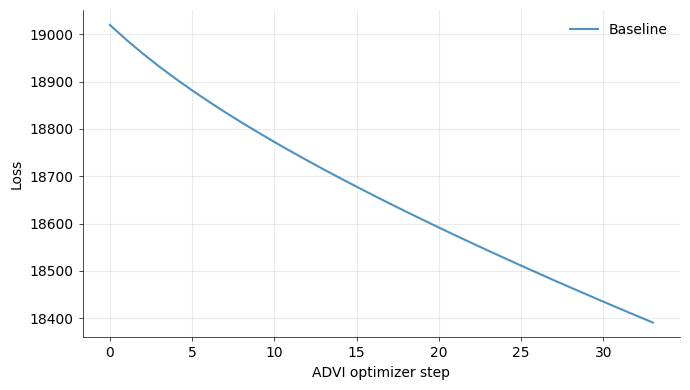

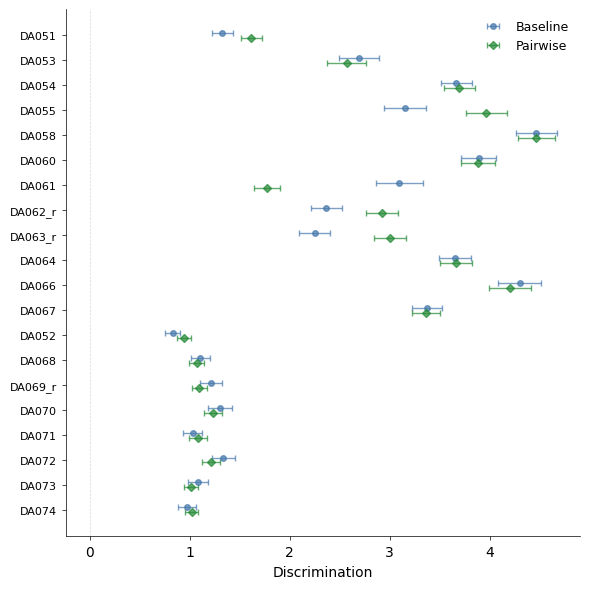

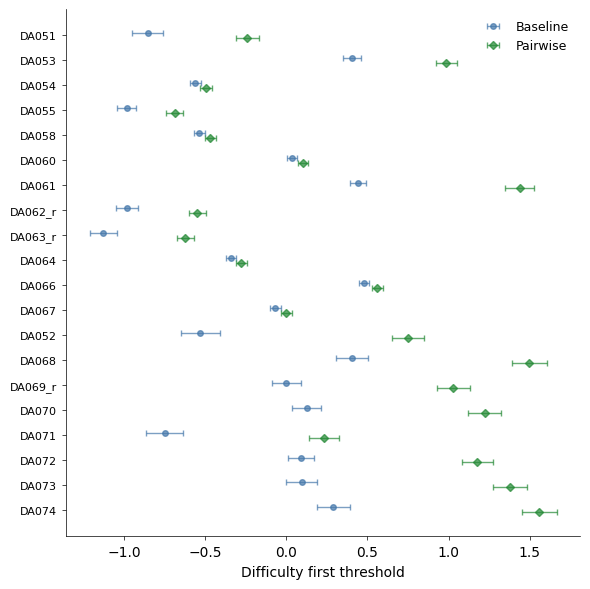

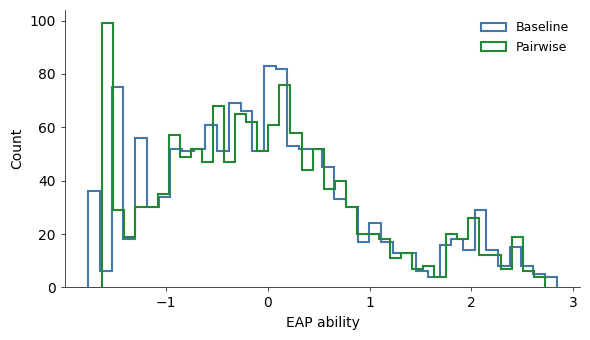

In [14]:
def _tufte(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.5)
    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)


def plot_forest(item_keys, variant_stats, param_key, xlabel):
    if not all(param_key in stats for stats in variant_stats.values()):
        print(f"  Skipping {param_key} forest plot: parameter missing.")
        return

    n_items = len(item_keys)
    fig, ax = plt.subplots(figsize=(6, max(4, n_items * 0.3)))
    y_pos = np.arange(n_items)
    n_models = len(variant_stats)

    for k, (label, stats) in enumerate(variant_stats.items()):
        mean = np.asarray(stats[param_key]["mean"]).reshape(-1)
        std = np.asarray(stats[param_key]["std"]).reshape(-1)

        if mean.size < n_items:
            print(f"  Skipping {label} in {param_key} plot: expected {n_items}, got {mean.size}")
            continue

        mean = mean[:n_items]
        std = std[:n_items]

        offset = (k - n_models / 2 + 0.5) * 0.2

        ax.errorbar(
            mean, y_pos + offset, xerr=std,
            fmt=MARKERS.get(label, "o"), capsize=2, markersize=4, elinewidth=1,
            color=COLORS.get(label, "gray"), alpha=0.7, label=label,
        )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(item_keys, fontsize=max(5, 9 - n_items // 20))
    ax.set_xlabel(xlabel)

    if param_key == "discriminations":
        ax.axvline(x=0, color="gray", linestyle="--", alpha=0.3, linewidth=0.5)

    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=9)
    _tufte(ax)
    plt.tight_layout()
    plt.show()


def plot_ability_histogram(eap_dict):
    fig, ax = plt.subplots(figsize=(6, 3.5))

    for label, eap in eap_dict.items():
        ax.hist(
            np.asarray(eap).reshape(-1), bins=40, histtype="step",
            linewidth=1.5, label=label, color=COLORS.get(label, "gray"),
        )

    ax.set_xlabel("EAP ability")
    ax.set_ylabel("Count")
    ax.legend(frameon=False, fontsize=9)
    _tufte(ax)
    plt.tight_layout()
    plt.show()


def plot_advi_losses(loss_dict):
    fig, ax = plt.subplots(figsize=(7, 4))
    any_losses = False

    for label, losses in loss_dict.items():
        losses = np.asarray(losses)
        if losses.size == 0:
            continue
        any_losses = True
        ax.plot(losses, label=label, alpha=0.8)

    if not any_losses:
        plt.close(fig)
        return

    ax.set_xlabel("ADVI optimizer step")
    ax.set_ylabel("Loss")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    _tufte(ax)
    plt.tight_layout()
    plt.show()


variant_stats = {"Baseline": baseline_res["stats"], "Pairwise": pairwise_res["stats"]}
variant_eap = {"Baseline": baseline_res["eap"], "Pairwise": pairwise_res["eap"]}

plot_advi_losses({"Baseline": baseline_res["advi_losses"], "Pairwise": pairwise_res["advi_losses"]})
plot_forest(item_keys, variant_stats, "discriminations", "Discrimination")
plot_forest(item_keys, variant_stats, "difficulties0", "Difficulty first threshold")
plot_ability_histogram(variant_eap)


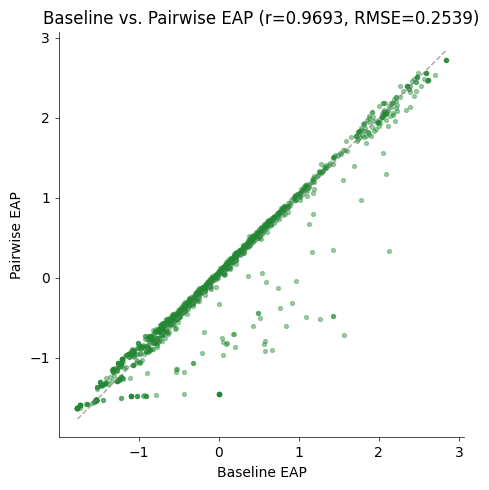

Pearson correlation (Baseline vs. Pairwise EAP): 0.9693
RMSE (Baseline vs. Pairwise EAP): 0.2539


In [15]:
# Baseline vs. Pairwise EAP scatter (one point per person), with Pearson r and RMSE.
baseline_eap = np.asarray(baseline_res["eap"]).reshape(-1)
pairwise_eap = np.asarray(pairwise_res["eap"]).reshape(-1)

pearson_r = float(np.corrcoef(baseline_eap, pairwise_eap)[0, 1])
rmse = float(np.sqrt(np.mean((baseline_eap - pairwise_eap) ** 2)))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(baseline_eap, pairwise_eap, s=8, alpha=0.4, color=COLORS["Pairwise"])

lo = min(baseline_eap.min(), pairwise_eap.min())
hi = max(baseline_eap.max(), pairwise_eap.max())
ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1, alpha=0.7)

ax.set_xlabel("Baseline EAP")
ax.set_ylabel("Pairwise EAP")
ax.set_title(f"Baseline vs. Pairwise EAP (r={pearson_r:.4f}, RMSE={rmse:.4f})")
ax.set_aspect("equal", adjustable="box")
_tufte(ax)
plt.tight_layout()
plt.show()

print(f"Pearson correlation (Baseline vs. Pairwise EAP): {pearson_r:.4f}")
print(f"RMSE (Baseline vs. Pairwise EAP): {rmse:.4f}")


## Section 7 — Save outputs

Single-scale equivalent of the reference script's `scale_summary.npz`
block, dropping anything `group_ids`/`sample_weights`-related. No
`abilities_combined.npz` / `scale_summary.csv` across scales -- with one
scale there is nothing to combine.

In [16]:
def save_npz(path, **kwargs):
    path = Path(path).expanduser()
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, **kwargs)


save_npz(
    OUTPUT_PATH / "scale_summary.npz",
    item_keys=np.array(item_keys),
    baseline_eap=baseline_res["eap"],
    pairwise_eap=pairwise_res["eap"],
    baseline_psd=baseline_res["psd"],
    pairwise_psd=pairwise_res["psd"],
    baseline_max_rhat=np.array(baseline_res["max_rhat"]),
    pairwise_max_rhat=np.array(pairwise_res["max_rhat"]),
    baseline_model_path=np.array(str(baseline_res["model_path"])),
    pairwise_model_path=np.array(str(pairwise_res["model_path"])),
    bcm_model_path=np.array(str(bcm_dir)),
    bcm_source=np.array(BCM_SOURCE),
    advi_requested_iterations=np.array(ADVI_ITERATIONS),
    baseline_advi_was_run=np.array(baseline_res["advi_was_run"]),
    pairwise_advi_was_run=np.array(pairwise_res["advi_was_run"]),
    baseline_step_size=np.array(baseline_res["mcmc_step_size"]),
    pairwise_step_size=np.array(pairwise_res["mcmc_step_size"]),
    baseline_target_accept_prob=np.array(baseline_res["mcmc_target_accept_prob"]),
    pairwise_target_accept_prob=np.array(pairwise_res["mcmc_target_accept_prob"]),
    baseline_pearson_r_vs_pairwise=np.array(pearson_r),
    baseline_pairwise_rmse=np.array(rmse),
)

print(f"Saved outputs to {OUTPUT_PATH / 'scale_summary.npz'}")


Saved outputs to /home/luis/CGE/mice_imp/data_wdfab/wdfab_results/scale_summary.npz
